# FASE 2 - VERIFICAÇÃO DAS IMAGENS DO DATASET


In [ ]:
# FASE 2 - PREPARAÇÃO DO AMBIENTE E CARREGAMENTO DO DATASET
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from google.colab import files

pasta_dataset = Path('/content/dataset_screws')

# Se o dataset ainda não estiver presente nesta sessão, envie o ZIP original.
if not pasta_dataset.exists() or not any(
    p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'}
    for p in pasta_dataset.rglob('*') if p.is_file()
):
    print('Selecione o ZIP original do dataset de parafusos.')
    uploaded = files.upload()
    arquivo_zip = next(iter(uploaded.keys()))
    pasta_dataset.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(arquivo_zip, 'r') as zip_ref:
        zip_ref.extractall(pasta_dataset)

print('Ambiente pronto! Dataset em:', pasta_dataset)


In [ ]:
from pathlib import Path

# Definir o caminho do dataset
pasta_dataset = Path('/content/dataset_screws')

# Verificar se a pasta existe
if pasta_dataset.exists():
    print("Dataset encontrado com sucesso!")
else:
    print("Dataset não encontrado. É necessário carregá-lo primeiro.")

Dataset encontrado com sucesso!


In [ ]:
# FASE 2 - VERIFICAÇÃO DAS IMAGENS DO DATASET

# Extensões de imagem permitidas
extensoes = ['.jpg', '.jpeg', '.png', '.bmp']

# Localizar todas as imagens dentro do dataset
imagens = [
    p for p in pasta_dataset.rglob('*')
    if p.is_file() and p.suffix.lower() in extensoes
]

# Organizar os caminhos em ordem
imagens = sorted(imagens)

# Mostrar a quantidade de imagens encontradas
print("Total de imagens encontradas:", len(imagens))

# Mostrar os caminhos das 5 primeiras imagens
print("\nExemplos de imagens:")

for img in imagens[:5]:

    print(img)

# Verificar se alguma imagem foi encontrada
if not imagens:
    raise ValueError("Nenhuma imagem foi encontrada no dataset!")

Total de imagens encontradas: 192

Exemplos de imagens:
/content/dataset_screws/test/images/frame_20230530_091814_jpg.rf.8f4af494d17651a1a38a4521ed1f739c.jpg
/content/dataset_screws/test/images/frame_20230530_092310_jpg.rf.438336b9b229f379396d4f0fad46f0ff.jpg
/content/dataset_screws/test/images/frame_20230615_135703_jpg.rf.b2938501a60400a7eae62465820f6cc3.jpg
/content/dataset_screws/test/images/frame_20230620_133947_jpg.rf.f415f2f265ae152ccdc280e144898a35.jpg
/content/dataset_screws/test/images/frame_20230622_095103_jpg.rf.76203fb999b4b4dbbc40ec3e0ea1d0f0.jpg


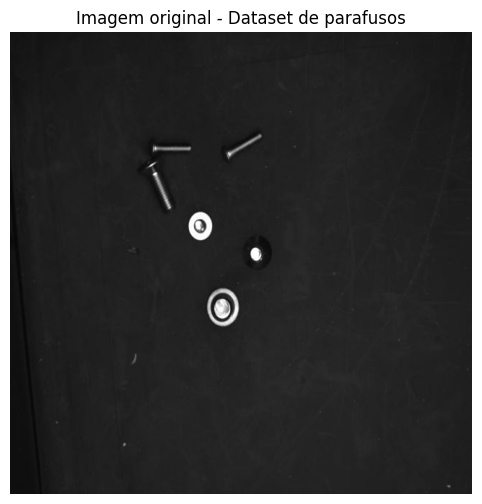

Imagem: frame_20230530_091814_jpg.rf.8f4af494d17651a1a38a4521ed1f739c.jpg
Dimensões: (640, 640, 3)


In [ ]:
# FASE 2 - VISUALIZAÇÃO DA IMAGEM ORIGINAL

# Selecionar a primeira imagem do dataset
caminho_imagem = imagens[0]

# Carregar a imagem com OpenCV
imagem_original = cv2.imread(str(caminho_imagem))

# Verificar se a imagem foi carregada
if imagem_original is None:
    raise ValueError("Não foi possível carregar a imagem.")

# Converter de BGR para RGB
imagem_rgb = cv2.cvtColor(
    imagem_original,
    cv2.COLOR_BGR2RGB
)

# Exibir a imagem
plt.figure(figsize=(8, 6))
plt.imshow(imagem_rgb)
plt.title("Imagem original - Dataset de parafusos")
plt.axis("off")
plt.show()

# Mostrar informações da imagem
print("Imagem:", caminho_imagem.name)
print("Dimensões:", imagem_original.shape)

Imagem carregada com sucesso!
Dimensões: (640, 640, 3)


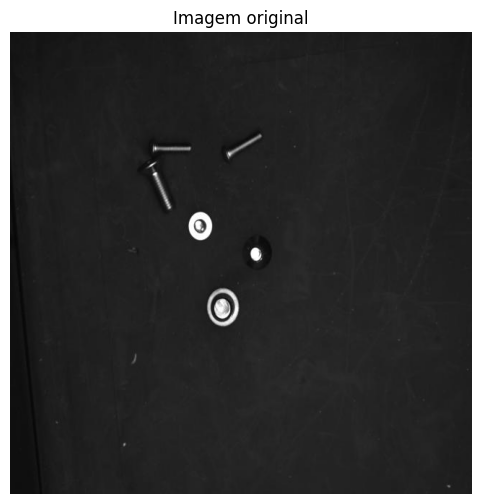

In [ ]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Caminho da imagem que utilizamos anteriormente
caminho_imagem = Path(
    "/content/dataset_screws/test/images/"
    "frame_20230530_091814_jpg.rf.8f4af494d17651a1a38a4521ed1f739c.jpg"
)

# Carregar a imagem
imagem_original = cv2.imread(str(caminho_imagem))

# Verificar se carregou corretamente
if imagem_original is None:
    raise FileNotFoundError(
        "Imagem não encontrada. Verifique se o dataset está no Colab."
    )

# Converter para RGB apenas para visualização
imagem_rgb = cv2.cvtColor(
    imagem_original,
    cv2.COLOR_BGR2RGB
)

print("Imagem carregada com sucesso!")
print("Dimensões:", imagem_original.shape)

plt.figure(figsize=(6, 6))
plt.imshow(imagem_rgb)
plt.title("Imagem original")
plt.axis("off")
plt.show()

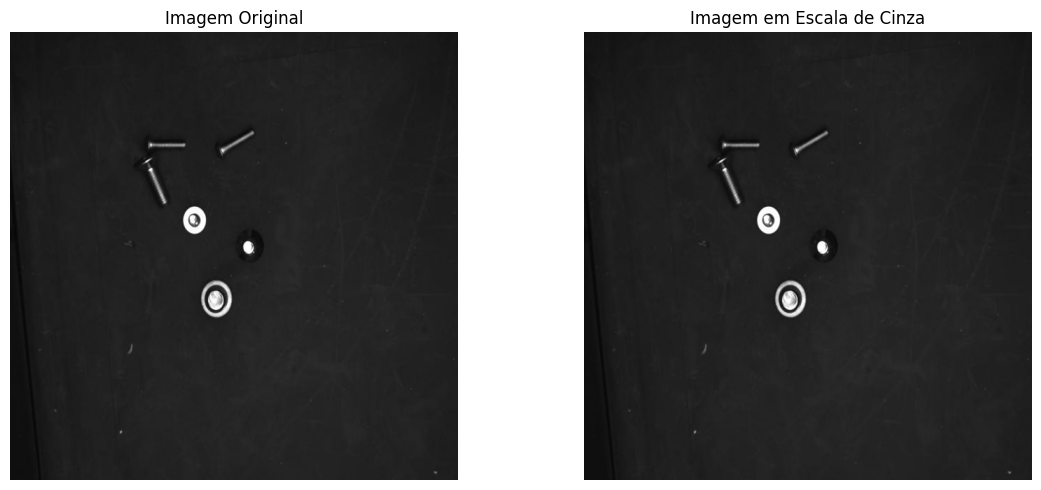

Dimensões da imagem original: (640, 640, 3)
Dimensões da imagem em cinza: (640, 640)


In [ ]:
# FASE 2 - CONVERSÃO PARA ESCALA DE CINZA

# Converter imagem original para escala de cinza
imagem_cinza = cv2.cvtColor(
    imagem_original,
    cv2.COLOR_BGR2GRAY
)

# Comparar imagem original e imagem em escala de cinza
plt.figure(figsize=(12, 5))

# Imagem original
plt.subplot(1, 2, 1)
plt.imshow(imagem_rgb)
plt.title("Imagem Original")
plt.axis("off")

# Imagem em escala de cinza
plt.subplot(1, 2, 2)
plt.imshow(imagem_cinza, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem em Escala de Cinza")
plt.axis("off")

plt.tight_layout()
plt.show()

# Informações da conversão
print("Dimensões da imagem original:", imagem_original.shape)
print("Dimensões da imagem em cinza:", imagem_cinza.shape)

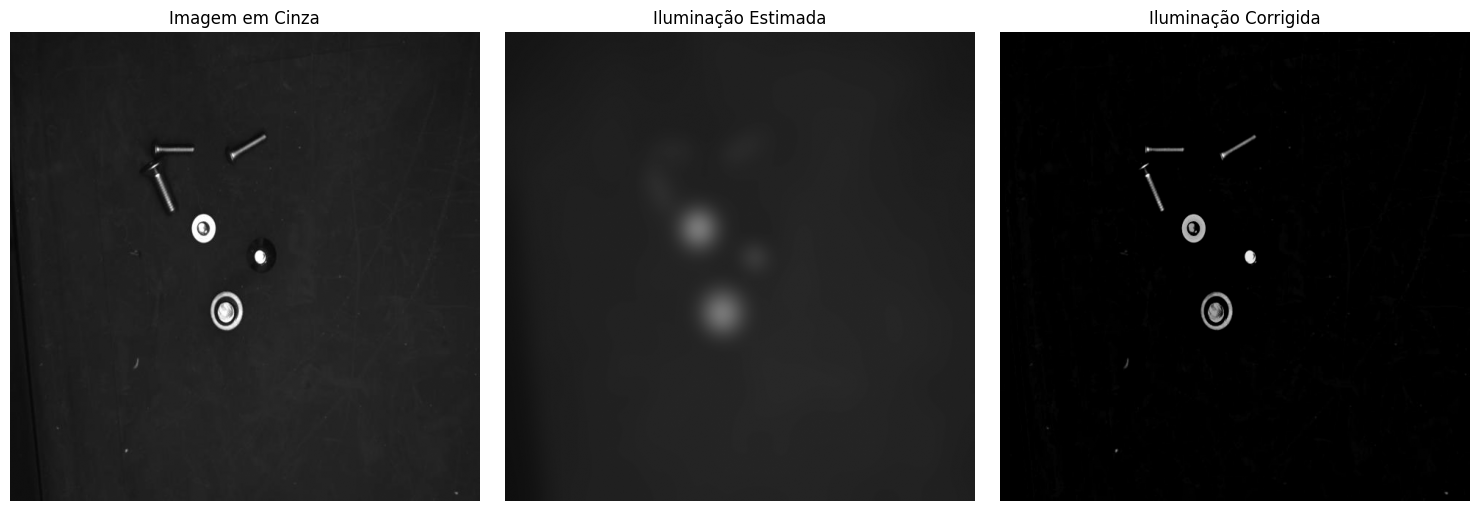

In [ ]:
# FASE 2 - CORREÇÃO DA ILUMINAÇÃO

# Estimar a iluminação do fundo com um filtro gaussiano
fundo_estimado = cv2.GaussianBlur(
    imagem_cinza,
    (101, 101),
    0
)

# Corrigir a iluminação por subtração do fundo
imagem_corrigida = cv2.subtract(
    imagem_cinza,
    fundo_estimado
)

# Normalizar os valores para o intervalo de 0 a 255
imagem_corrigida = cv2.normalize(
    imagem_corrigida,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

# Comparar os resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_cinza, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem em Cinza")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(fundo_estimado, cmap="gray", vmin=0, vmax=255)
plt.title("Iluminação Estimada")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagem_corrigida, cmap="gray", vmin=0, vmax=255)
plt.title("Iluminação Corrigida")
plt.axis("off")

plt.tight_layout()
plt.show()

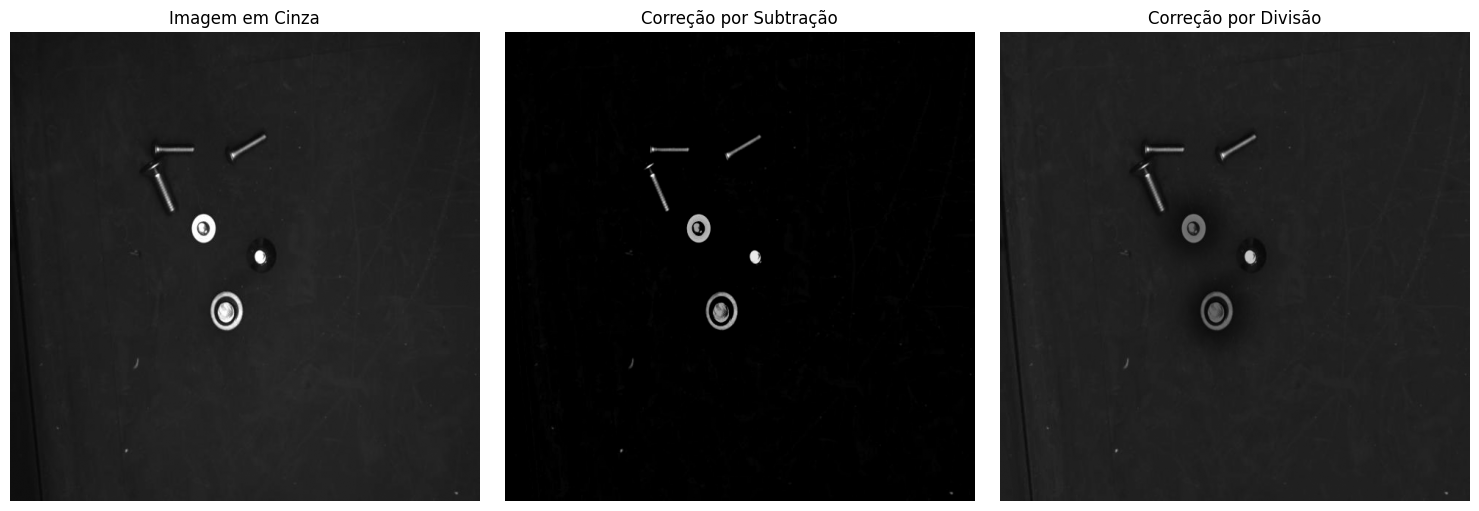

In [ ]:
# FASE 2 - CORREÇÃO DE ILUMINAÇÃO POR DIVISÃO

# Estimar a iluminação do fundo
fundo_estimado_div = cv2.GaussianBlur(
    imagem_cinza,
    (151, 151),
    0
)

# Evitar divisão por zero
fundo_seguro = np.maximum(
    fundo_estimado_div.astype(np.float32),
    1.0
)

# Corrigir a iluminação
imagem_dividida = (
    imagem_cinza.astype(np.float32)
    / fundo_seguro
) * np.mean(fundo_seguro)

# Limitar os valores ao intervalo permitido
imagem_dividida = np.clip(
    imagem_dividida, 0, 255
).astype(np.uint8)

# Comparar as técnicas
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_cinza, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem em Cinza")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagem_corrigida, cmap="gray", vmin=0, vmax=255)
plt.title("Correção por Subtração")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagem_dividida, cmap="gray", vmin=0, vmax=255)
plt.title("Correção por Divisão")
plt.axis("off")

plt.tight_layout()
plt.show()

### Análise da correção de iluminação

Foram testadas duas técnicas de correção de iluminação:

**1. Correção por subtração**

A iluminação do fundo foi estimada utilizando um filtro
gaussiano e posteriormente subtraída da imagem em escala
de cinza.

O resultado apresentou um fundo bastante escuro,
mas houve perda de detalhes em algumas regiões dos objetos.

**2. Correção por divisão**

A imagem foi normalizada em relação à iluminação
estimada por um filtro gaussiano.

Essa abordagem apresentou melhor preservação visual
dos objetos, incluindo regiões mais escuras.

**Conclusão preliminar:**

A correção por divisão foi selecionada como candidata
para as próximas etapas do pré-processamento.

A escolha definitiva dependerá da avaliação dos
resultados de segmentação e contagem.

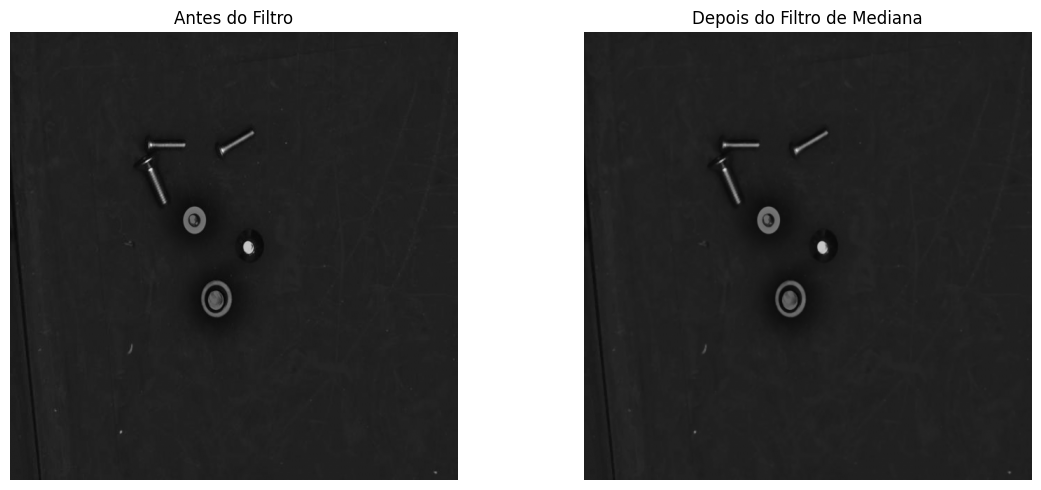

In [ ]:
# FASE 2 - REDUÇÃO DE RUÍDOS
# TESTE 1 - FILTRO DE MEDIANA

# Aplicar filtro de mediana
imagem_mediana = cv2.medianBlur(
    imagem_dividida,
    3
)

# Comparar as imagens
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagem_dividida, cmap="gray", vmin=0, vmax=255)
plt.title("Antes do Filtro")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagem_mediana, cmap="gray", vmin=0, vmax=255)
plt.title("Depois do Filtro de Mediana")
plt.axis("off")

plt.tight_layout()
plt.show()

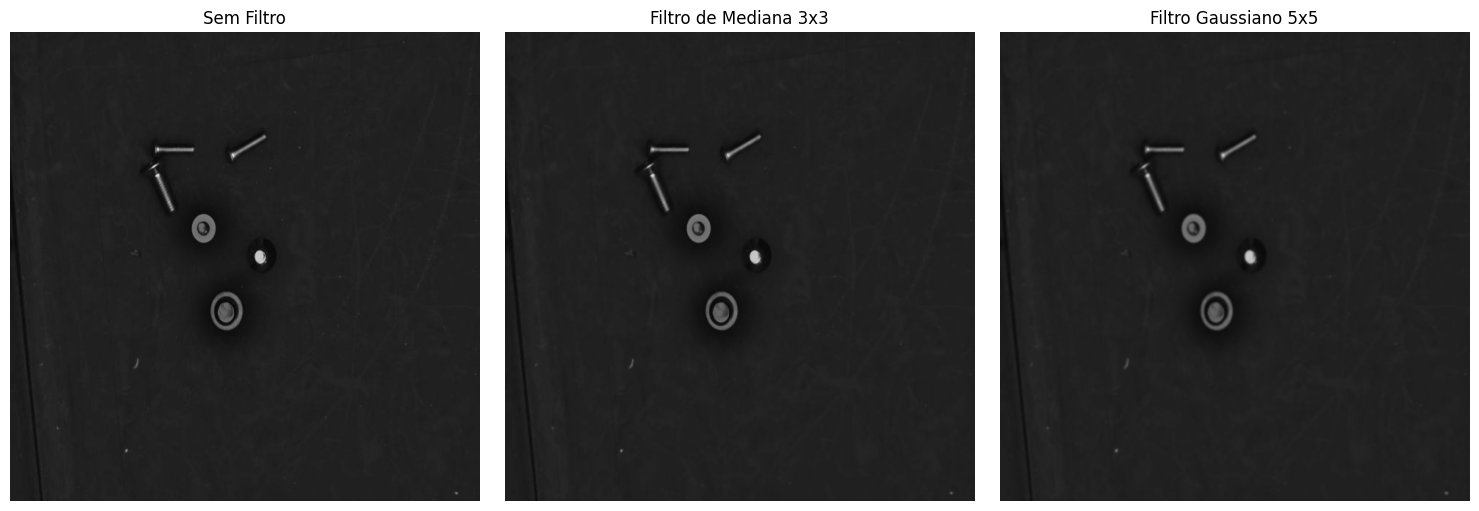

In [ ]:
# FASE 2 - REDUÇÃO DE RUÍDOS
# TESTE 2 - FILTRO GAUSSIANO

# Aplicar filtro gaussiano
imagem_gaussiana = cv2.GaussianBlur(
    imagem_dividida,
    (5, 5),
    0
)

# Comparar os filtros
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_dividida, cmap="gray", vmin=0, vmax=255)
plt.title("Sem Filtro")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagem_mediana, cmap="gray", vmin=0, vmax=255)
plt.title("Filtro de Mediana 3x3")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagem_gaussiana, cmap="gray", vmin=0, vmax=255)
plt.title("Filtro Gaussiano 5x5")
plt.axis("off")

plt.tight_layout()
plt.show()

### Análise dos filtros de redução de ruído

Foram aplicados dois filtros sobre a imagem com
correção de iluminação por divisão:

**Filtro de Mediana (3x3):**
Apresentou uma suavização discreta, sem alterações
visuais significativas nos contornos dos objetos.

**Filtro Gaussiano (5x5):**
Produziu uma imagem aparentemente mais suavizada,
com possível redução da nitidez das bordas.

**Conclusão preliminar:**
O filtro de mediana 3x3 foi selecionado como candidato
para as próximas etapas, devido à preservação visual
dos detalhes dos objetos.

A escolha definitiva dependerá de uma avaliação
quantitativa e dos resultados da segmentação.

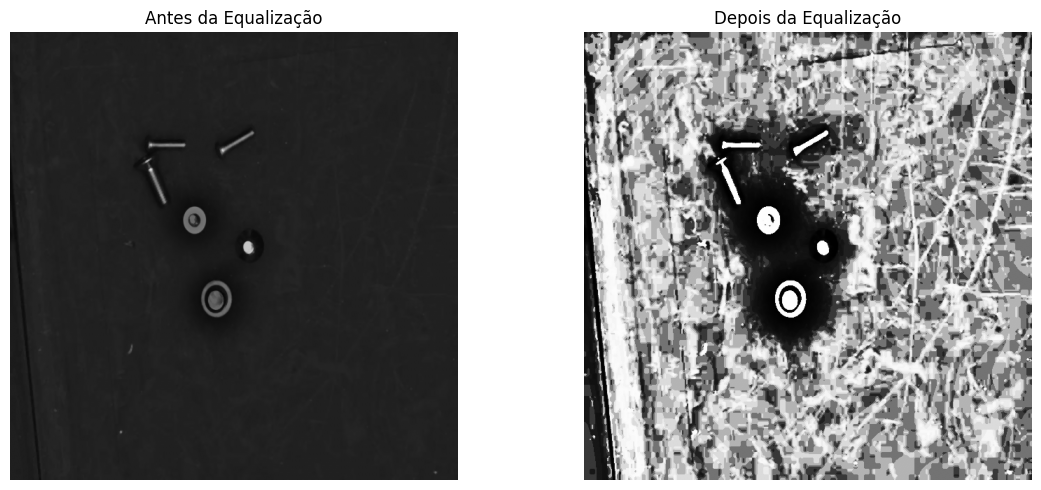

In [ ]:
# FASE 2 - EQUALIZAÇÃO DO HISTOGRAMA
# TESTE 1 - EQUALIZAÇÃO TRADICIONAL

# Aplicar equalização do histograma
imagem_equalizada = cv2.equalizeHist(
    imagem_mediana
)

# Comparar as imagens
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagem_mediana, cmap="gray", vmin=0, vmax=255)
plt.title("Antes da Equalização")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagem_equalizada, cmap="gray", vmin=0, vmax=255)
plt.title("Depois da Equalização")
plt.axis("off")

plt.tight_layout()
plt.show()

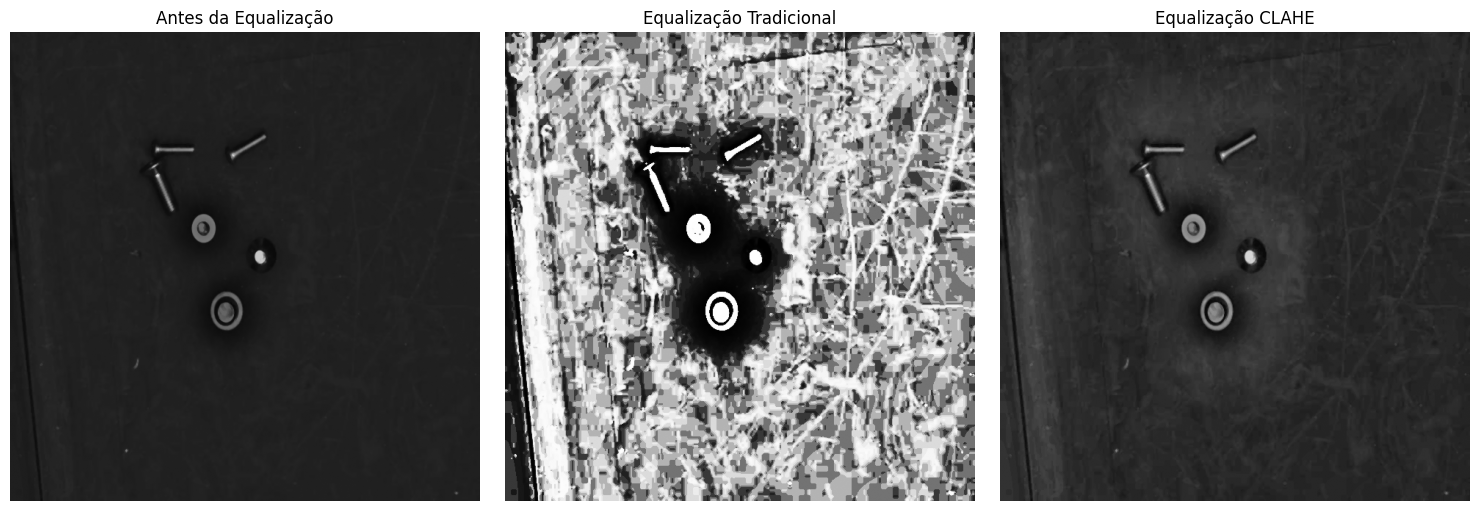

In [ ]:
# FASE 2 - EQUALIZAÇÃO ADAPTATIVA
# TESTE 2 - CLAHE

# Criar o método CLAHE
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Aplicar na imagem filtrada
imagem_clahe = clahe.apply(imagem_mediana)

# Comparar as três imagens
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_mediana, cmap="gray", vmin=0, vmax=255)
plt.title("Antes da Equalização")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagem_equalizada, cmap="gray", vmin=0, vmax=255)
plt.title("Equalização Tradicional")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagem_clahe, cmap="gray", vmin=0, vmax=255)
plt.title("Equalização CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

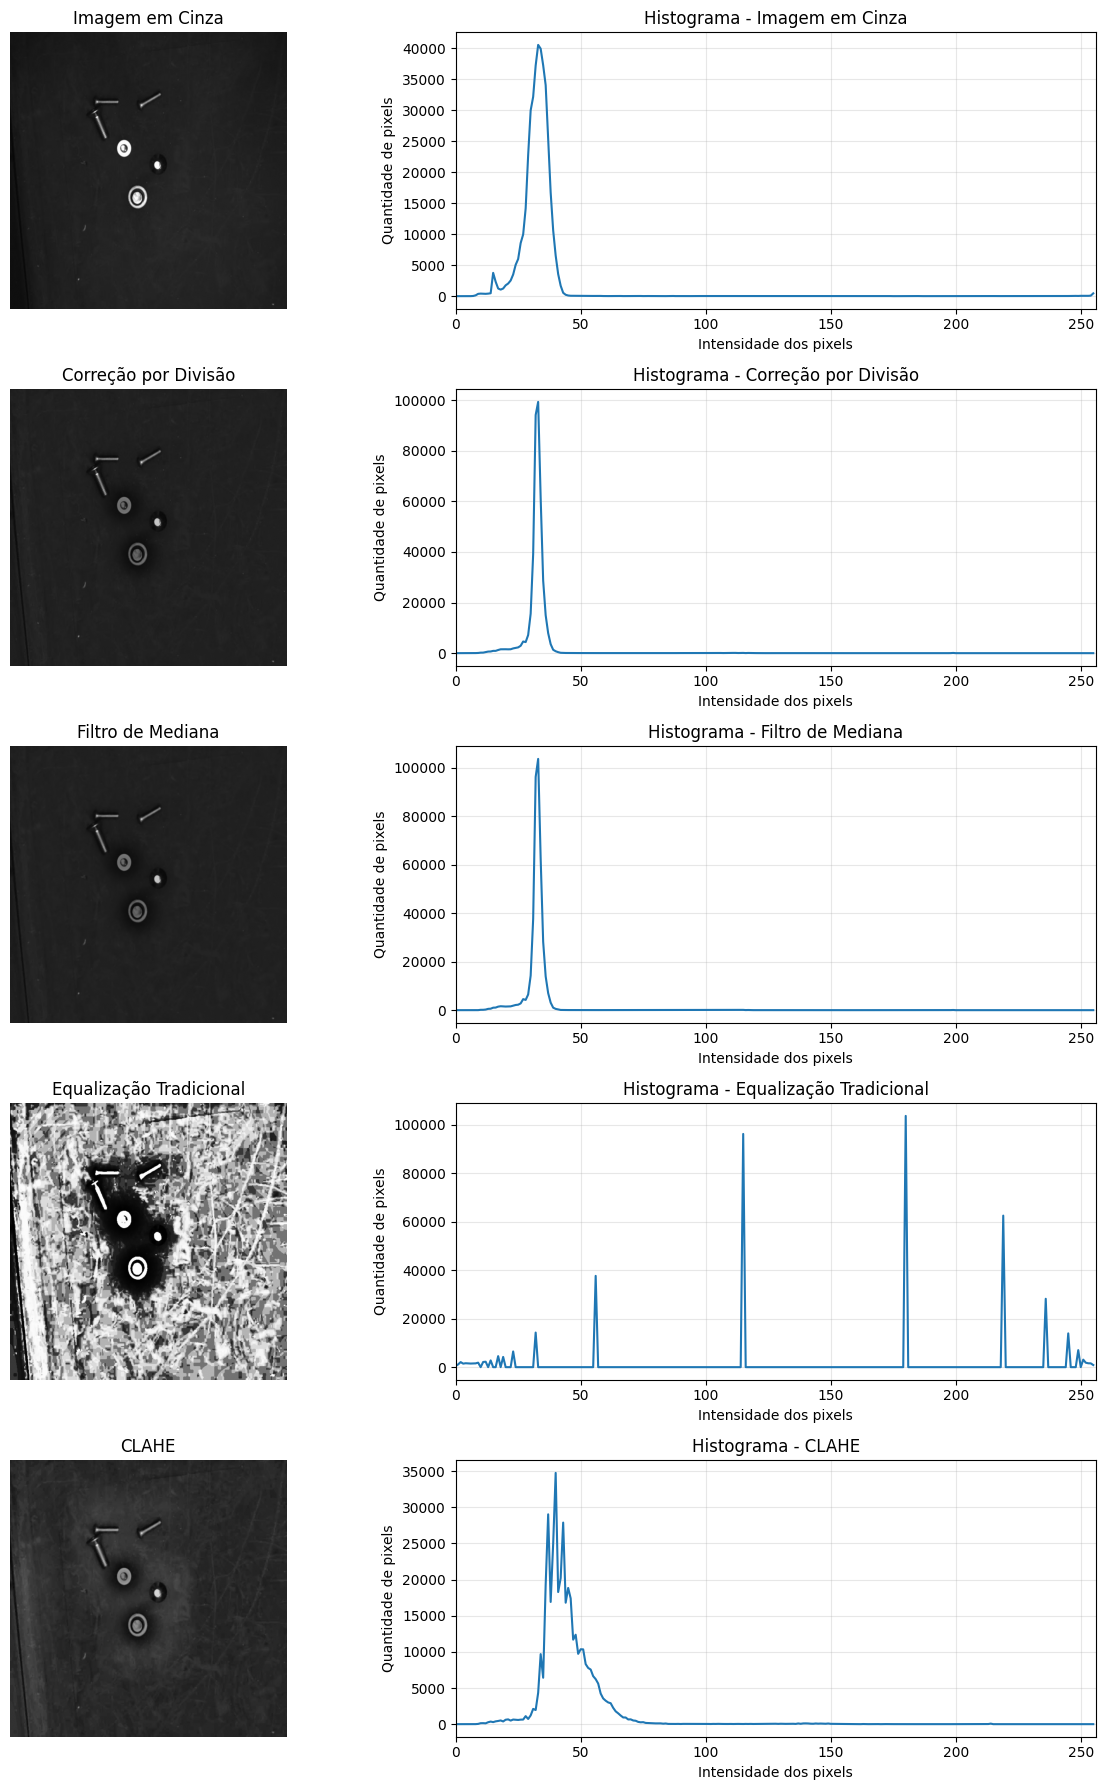

In [ ]:
# FASE 2 - ANÁLISE DOS HISTOGRAMAS

# Imagens que serão comparadas
imagens_comparacao = [
    ("Imagem em Cinza", imagem_cinza),
    ("Correção por Divisão", imagem_dividida),
    ("Filtro de Mediana", imagem_mediana),
    ("Equalização Tradicional", imagem_equalizada),
    ("CLAHE", imagem_clahe)
]

# Criar figura com 5 linhas e 2 colunas
fig, axes = plt.subplots(5, 2, figsize=(13, 18))

for i, (titulo, imagem) in enumerate(imagens_comparacao):

    # Exibir imagem
    axes[i, 0].imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i, 0].set_title(titulo)
    axes[i, 0].axis("off")

    # Calcular o histograma
    histograma = cv2.calcHist(
        [imagem],
        [0],
        None,
        [256],
        [0, 256]
    )

    # Exibir o histograma
    axes[i, 1].plot(histograma)
    axes[i, 1].set_title("Histograma - " + titulo)
    axes[i, 1].set_xlabel("Intensidade dos pixels")
    axes[i, 1].set_ylabel("Quantidade de pixels")
    axes[i, 1].set_xlim([0, 256])
    axes[i, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Análise dos histogramas

Foram analisados os histogramas de cinco versões
da imagem: escala de cinza, correção por divisão,
filtro de mediana, equalização tradicional e CLAHE.

**Imagem em escala de cinza:**
Apresentou maior concentração de pixels nas
intensidades baixas, devido ao fundo escuro.

**Correção de iluminação por divisão:**
Apresentou uma concentração mais estreita
das intensidades predominantes do fundo.

**Filtro de mediana:**
Manteve uma distribuição semelhante à imagem
anterior, indicando alterações discretas.

**Equalização tradicional:**
Redistribuiu intensamente os níveis de cinza,
mas também destacou riscos e irregularidades
do fundo, dificultando visualmente a separação
entre objetos e cenário.

**Equalização CLAHE:**
Produziu uma redistribuição mais moderada
das intensidades, preservando melhor a
aparência dos objetos.

**Conclusão preliminar:**
O CLAHE apresentou um resultado visual mais
adequado que a equalização tradicional.

Entretanto, a definição do melhor método de
pré-processamento dependerá de testes de
segmentação e contagem.

In [ ]:
# FASE 2 - AVALIAÇÃO QUANTITATIVA

import pandas as pd

resultados = []

for nome, imagem in imagens_comparacao:

    # Intensidade média
    media = np.mean(imagem)

    # Desvio padrão das intensidades
    desvio = np.std(imagem)

    # Variância do Laplaciano
    laplaciano = cv2.Laplacian(
        imagem,
        cv2.CV_64F
    )

    nitidez = laplaciano.var()

    resultados.append({
        "Técnica": nome,
        "Intensidade Média": round(media, 2),
        "Desvio Padrão": round(desvio, 2),
        "Variância Laplaciano": round(nitidez, 2)
    })

tabela_resultados = pd.DataFrame(resultados)

display(tabela_resultados)

,Técnica,Intensidade Média,Desvio Padrão,Variância Laplaciano
0,Imagem em Cinza,33.55,15.96,53.24
1,Correção por Divisão,32.80,8.12,22.15
2,Filtro de Mediana,32.78,7.90,14.83
3,Equalização Tradicional,147.75,73.96,3607.87
4,CLAHE,44.74,12.15,32.74


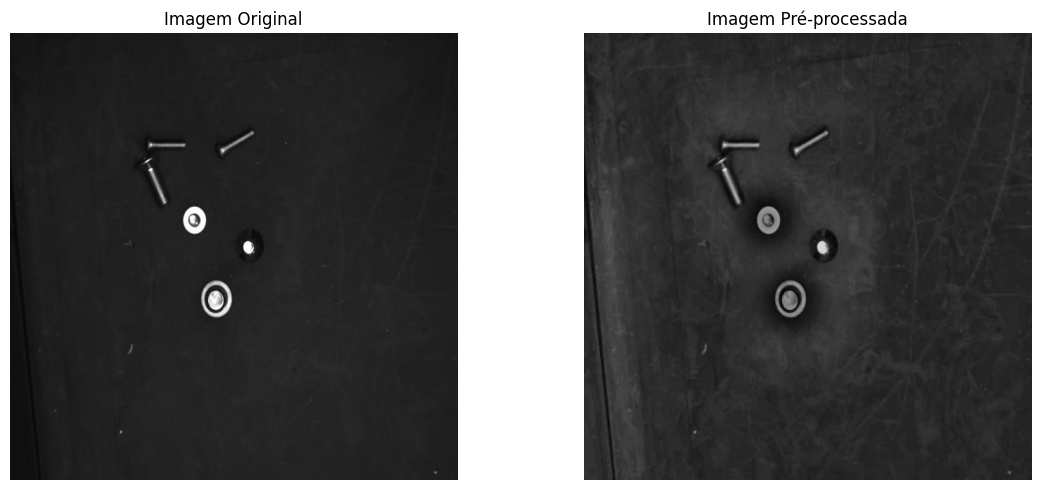

Dimensões finais: (640, 640)


In [ ]:
# FASE 2 - PIPELINE DE PRÉ-PROCESSAMENTO

def preprocessar_imagem(imagem_original):

    # 1. Conversão para escala de cinza
    imagem_cinza = cv2.cvtColor(
        imagem_original,
        cv2.COLOR_BGR2GRAY
    )

    # 2. Estimativa da iluminação
    fundo = cv2.GaussianBlur(
        imagem_cinza,
        (151, 151),
        0
    )

    # 3. Correção de iluminação por divisão
    fundo_seguro = np.maximum(
        fundo.astype(np.float32),
        1.0
    )

    imagem_corrigida = (
        imagem_cinza.astype(np.float32)
        / fundo_seguro
    ) * np.mean(fundo_seguro)

    imagem_corrigida = np.clip(
        imagem_corrigida,
        0,
        255
    ).astype(np.uint8)

    # 4. Redução de ruído com filtro de mediana
    imagem_filtrada = cv2.medianBlur(
        imagem_corrigida,
        3
    )

    # 5. Equalização adaptativa CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    imagem_final = clahe.apply(
        imagem_filtrada
    )

    return imagem_final


# Aplicar pipeline na imagem de teste
imagem_preprocessada = preprocessar_imagem(
    imagem_original
)

# Comparar original e pré-processada
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagem_rgb)
plt.title("Imagem Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    imagem_preprocessada,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Imagem Pré-processada")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Dimensões finais:", imagem_preprocessada.shape)

In [ ]:
# RECUPERAR A LISTA DE IMAGENS DO DATASET

from pathlib import Path

# Definir a pasta do dataset
pasta_dataset = Path('/content/dataset_screws')

# Verificar se a pasta existe
if not pasta_dataset.exists():
    raise FileNotFoundError(
        "Dataset não encontrado! É necessário extrair o ZIP novamente."
    )

# Localizar todas as imagens
extensoes = ['.jpg', '.jpeg', '.png', '.bmp']

imagens = sorted([
    p for p in pasta_dataset.rglob('*')
    if p.is_file() and p.suffix.lower() in extensoes
])

# Verificar se encontramos imagens
if not imagens:
    raise ValueError("Nenhuma imagem foi encontrada no dataset!")

print("Total de imagens encontradas:", len(imagens))
print("Primeira imagem:", imagens[0].name)

Total de imagens encontradas: 192
Primeira imagem: frame_20230530_091814_jpg.rf.8f4af494d17651a1a38a4521ed1f739c.jpg


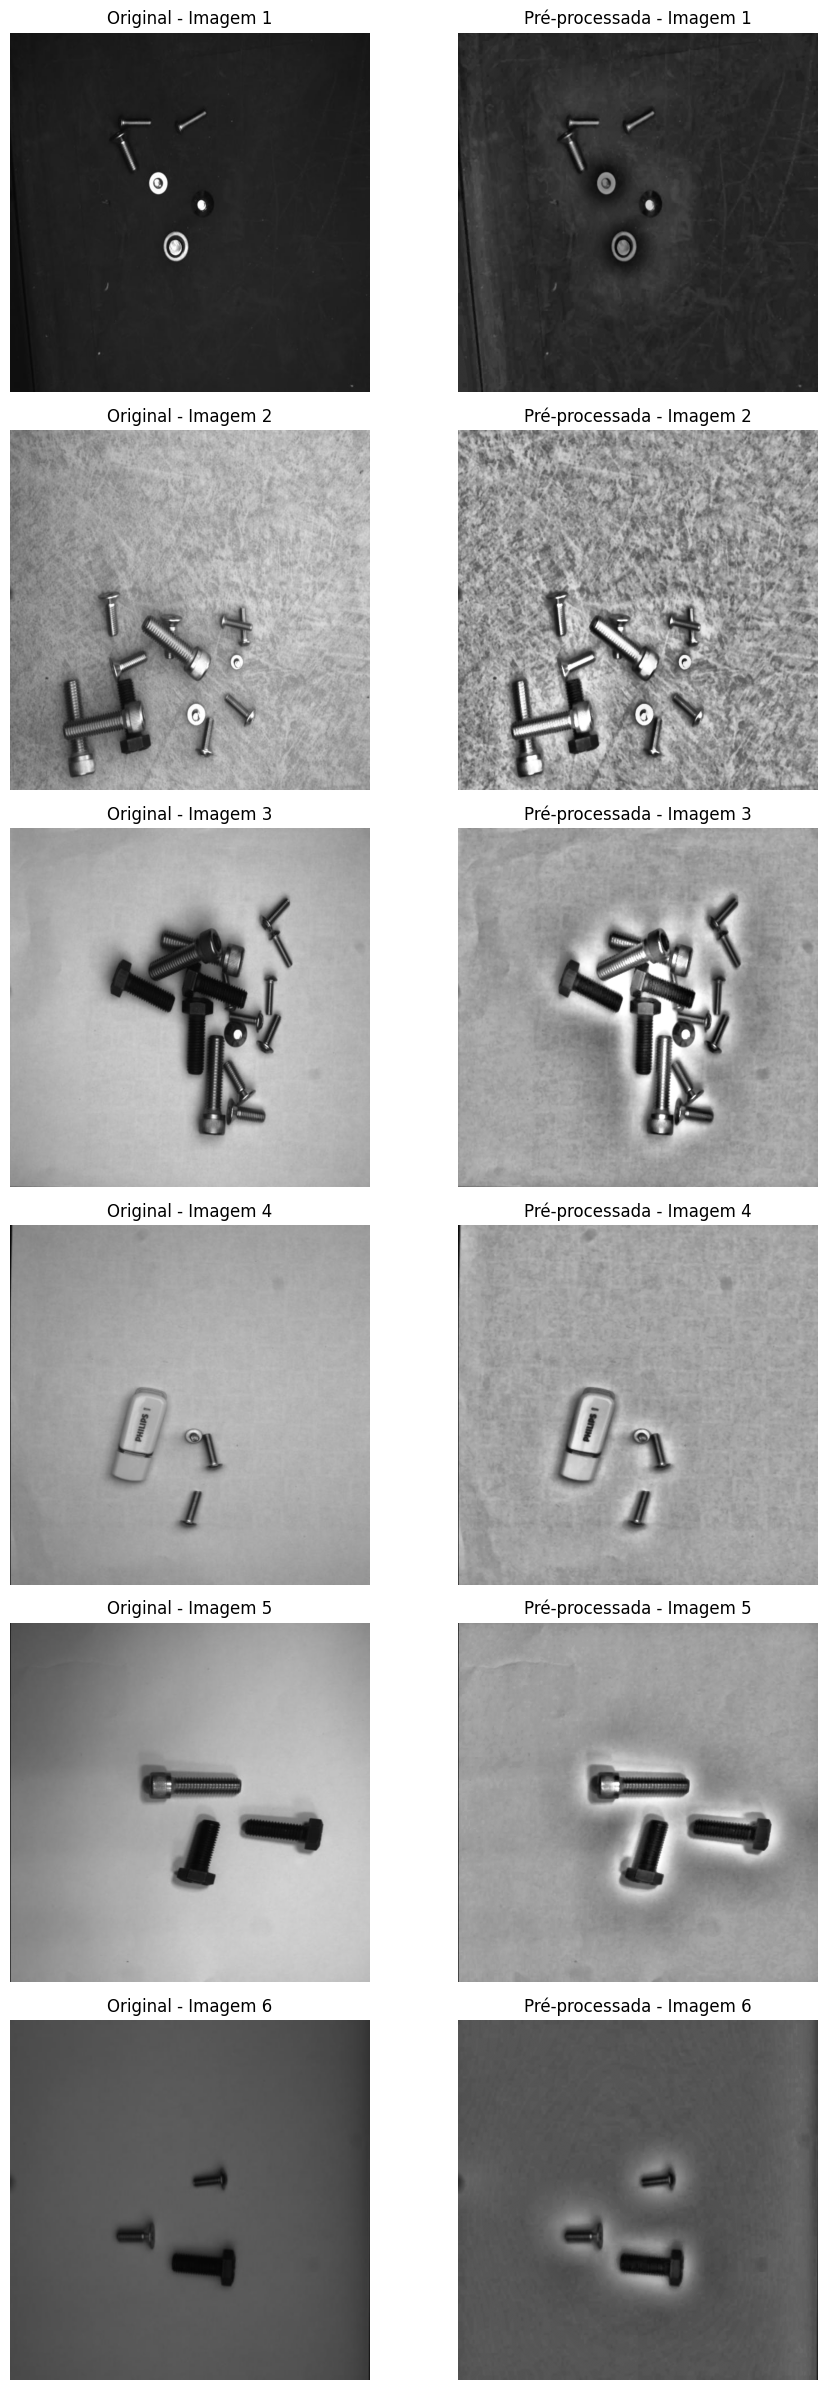

In [ ]:
# FASE 2 - TESTE DO PIPELINE EM MÚLTIPLAS IMAGENS

# Selecionar 6 imagens distribuídas pelo dataset
indices = np.linspace(
    0,
    len(imagens) - 1,
    6,
    dtype=int
)

imagens_teste = [imagens[i] for i in indices]

# Criar painel comparativo
fig, axes = plt.subplots(6, 2, figsize=(10, 24))

for i, caminho in enumerate(imagens_teste):

    # Carregar imagem
    original = cv2.imread(str(caminho))

    if original is None:
        raise ValueError(f"Erro ao carregar: {caminho}")

    # Aplicar pipeline
    processada = preprocessar_imagem(original)

    # Exibir imagem original
    axes[i, 0].imshow(
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    )

    axes[i, 0].set_title(f"Original - Imagem {i + 1}")
    axes[i, 0].axis("off")

    # Exibir imagem processada
    axes[i, 1].imshow(
        processada,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i, 1].set_title(f"Pré-processada - Imagem {i + 1}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

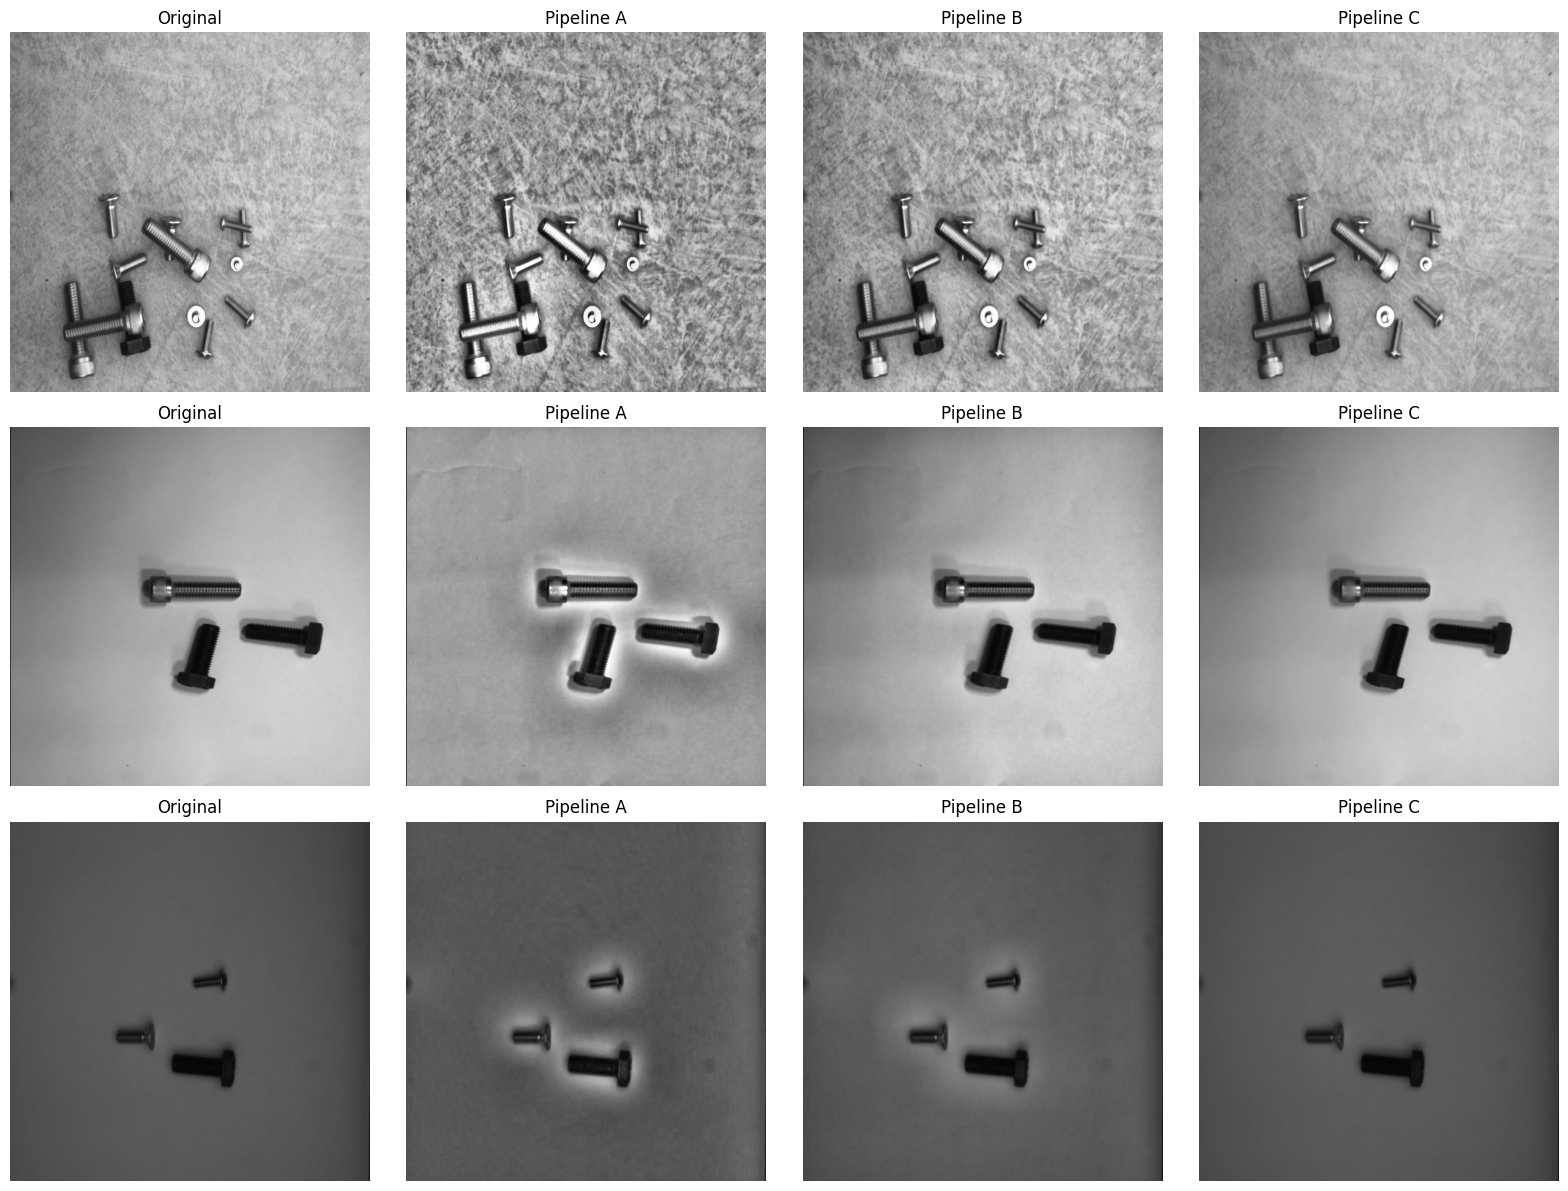

In [ ]:
# FASE 2 - COMPARAÇÃO DE PIPELINES

def preprocessar_suave(imagem):

    # Converter para escala de cinza
    cinza = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2GRAY
    )

    # Reduzir ruídos
    filtrada = cv2.medianBlur(cinza, 3)

    # CLAHE com menor intensidade
    clahe_suave = cv2.createCLAHE(
        clipLimit=1.0,
        tileGridSize=(8, 8)
    )

    return clahe_suave.apply(filtrada)


def preprocessar_sem_equalizacao(imagem):

    # Converter para escala de cinza
    cinza = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2GRAY
    )

    # Aplicar somente filtro de mediana
    return cv2.medianBlur(cinza, 3)


# Selecionar três imagens do teste anterior
# Imagens 2, 5 e 6
indices_teste = [1, 4, 5]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for linha, indice in enumerate(indices_teste):

    caminho = imagens_teste[indice]

    original = cv2.imread(str(caminho))

    # Pipeline A - Atual
    resultado_a = preprocessar_imagem(original)

    # Pipeline B - Suave
    resultado_b = preprocessar_suave(original)

    # Pipeline C - Sem equalização
    resultado_c = preprocessar_sem_equalizacao(original)

    resultados = [
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB),
        resultado_a,
        resultado_b,
        resultado_c
    ]

    titulos = [
        "Original",
        "Pipeline A",
        "Pipeline B",
        "Pipeline C"
    ]

    for coluna in range(4):

        if coluna == 0:
            axes[linha, coluna].imshow(resultados[coluna])
        else:
            axes[linha, coluna].imshow(
                resultados[coluna],
                cmap="gray",
                vmin=0,
                vmax=255
            )

        axes[linha, coluna].set_title(titulos[coluna])
        axes[linha, coluna].axis("off")

plt.tight_layout()
plt.show()

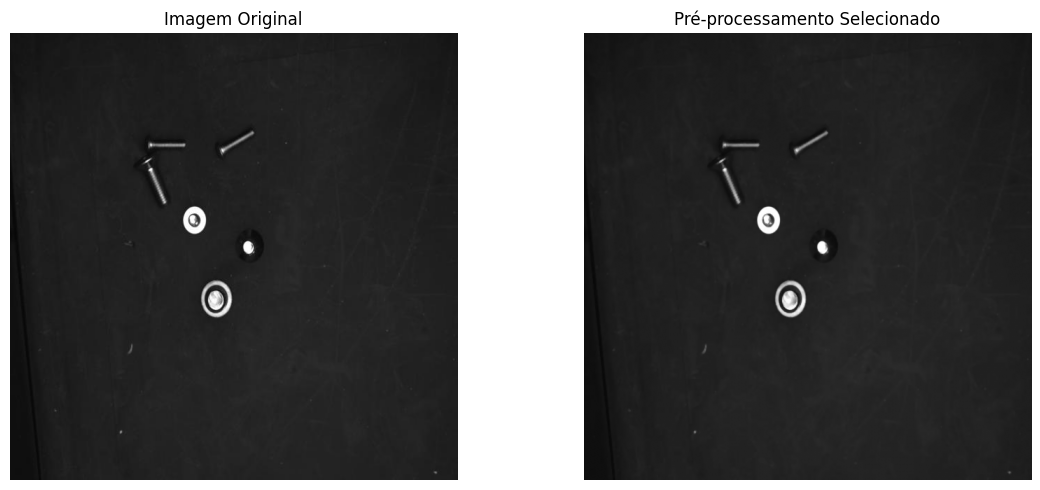

Dimensões finais: (640, 640)
Tipo de dados: uint8


In [ ]:
# FASE 2 - PIPELINE FINAL CANDIDATO
# Escala de cinza + filtro de mediana

def preprocessar_imagem_final(imagem_original):

    # 1. Converter para escala de cinza
    imagem_cinza = cv2.cvtColor(
        imagem_original,
        cv2.COLOR_BGR2GRAY
    )

    # 2. Aplicar filtro de mediana 3x3
    imagem_filtrada = cv2.medianBlur(
        imagem_cinza,
        3
    )

    return imagem_filtrada


# Testar na imagem original
imagem_final = preprocessar_imagem_final(
    imagem_original
)

# Visualizar o resultado
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagem_rgb)
plt.title("Imagem Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagem_final, cmap="gray", vmin=0, vmax=255)
plt.title("Pré-processamento Selecionado")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Dimensões finais:", imagem_final.shape)
print("Tipo de dados:", imagem_final.dtype)

In [ ]:
# FASE 2 - PROCESSAMENTO DO DATASET COMPLETO

from pathlib import Path
import cv2

# Pasta de saída das imagens processadas
pasta_saida = Path('/content/dataset_preprocessado')

# Contadores
total_processadas = 0
erros = []

for caminho_imagem in imagens:

    # Identificar o caminho relativo à pasta original
    caminho_relativo = caminho_imagem.relative_to(pasta_dataset)

    # Construir o caminho de saída
    destino = pasta_saida / caminho_relativo

    # Criar as pastas necessárias
    destino.parent.mkdir(parents=True, exist_ok=True)

    # Carregar a imagem original
    imagem = cv2.imread(str(caminho_imagem))

    if imagem is None:
        erros.append(str(caminho_imagem))
        continue

    # Aplicar o pipeline selecionado
    imagem_processada = preprocessar_imagem_final(imagem)

    # Salvar a imagem
    sucesso = cv2.imwrite(
        str(destino),
        imagem_processada
    )

    if sucesso:
        total_processadas += 1
    else:
        erros.append(str(caminho_imagem))

# Exibir resultados
print("Total de imagens originais:", len(imagens))
print("Total de imagens processadas:", total_processadas)
print("Total de erros:", len(erros))
print("Pasta de saída:", pasta_saida)

Total de imagens originais: 192
Total de imagens processadas: 192
Total de erros: 0
Pasta de saída: /content/dataset_preprocessado


In [ ]:
# FASE 2 - VALIDAÇÃO DO DATASET PRÉ-PROCESSADO

total_validadas = 0
problemas = []

for caminho_original in imagens:

    # Identificar o arquivo correspondente
    caminho_relativo = caminho_original.relative_to(pasta_dataset)
    caminho_processado = pasta_saida / caminho_relativo

    # Verificar se o arquivo existe
    if not caminho_processado.exists():
        problemas.append(f"Arquivo ausente: {caminho_relativo}")
        continue

    # Carregar as duas imagens
    original = cv2.imread(str(caminho_original))
    processada = cv2.imread(
        str(caminho_processado),
        cv2.IMREAD_UNCHANGED
    )

    if original is None or processada is None:
        problemas.append(f"Erro de leitura: {caminho_relativo}")
        continue

    # Verificar dimensões e canal de cinza
    if original.shape[:2] != processada.shape[:2]:
        problemas.append(f"Dimensões diferentes: {caminho_relativo}")
        continue

    if processada.ndim != 2:
        problemas.append(f"Não está em cinza: {caminho_relativo}")
        continue

    total_validadas += 1

print("Imagens validadas:", total_validadas)
print("Problemas encontrados:", len(problemas))

for problema in problemas[:10]:
    print(problema)

Imagens validadas: 192
Problemas encontrados: 0


In [ ]:
# FASE 2 - PREPARAÇÃO DO DATASET PARA ENTREGA

import shutil
from pathlib import Path

# Pasta de entrega
pasta_entrega = Path('/content/entrega_fase2')

# Recriar a pasta de entrega
if pasta_entrega.exists():
    shutil.rmtree(pasta_entrega)

pasta_entrega.mkdir(parents=True)

# Copiar as imagens pré-processadas
shutil.copytree(
    pasta_saida,
    pasta_entrega,
    dirs_exist_ok=True
)

# Copiar anotações originais
for pasta_labels in pasta_dataset.rglob('labels'):

    caminho_relativo = pasta_labels.relative_to(pasta_dataset)
    destino = pasta_entrega / caminho_relativo

    shutil.copytree(
        pasta_labels,
        destino,
        dirs_exist_ok=True
    )

# Copiar configuração das classes
arquivos_yaml = list(pasta_dataset.rglob('data.yaml'))

if len(arquivos_yaml) != 1:
    raise ValueError(
        f"Esperado 1 data.yaml, encontrados {len(arquivos_yaml)}."
    )

shutil.copy2(
    arquivos_yaml[0],
    pasta_entrega / 'data.yaml'
)

print("Pasta de entrega organizada!")

Pasta de entrega organizada!


In [ ]:
# COMPACTAR O DATASET PRÉ-PROCESSADO

import shutil
from google.colab import files

arquivo_final = shutil.make_archive(
    '/content/Fase2_Dataset_Preprocessado',
    'zip',
    root_dir='/content/entrega_fase2'
)

print("ZIP criado:", arquivo_final)

files.download(arquivo_final)

ZIP criado: /content/Fase2_Dataset_Preprocessado.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# FASE 2 — CONCLUSÕES DO PRÉ-PROCESSAMENTO

## 1. Objetivo

Esta etapa teve como objetivo aplicar e avaliar técnicas de pré-processamento nas imagens do dataset de objetos industriais, preparando-as para as próximas fases de segmentação, identificação e contagem.

## 2. Técnicas implementadas

**Conversão para escala de cinza:** as imagens foram convertidas de três canais BGR para um único canal de intensidade, simplificando o processamento.

**Correção de iluminação:** foram experimentados métodos de subtração e divisão pela iluminação estimada com filtro gaussiano.

**Redução de ruídos:** foram avaliados os filtros de mediana 3×3 e gaussiano 5×5.

**Equalização de histograma:** foram comparadas a equalização global tradicional e a equalização adaptativa CLAHE.

**Análise dos histogramas:** foram examinadas as distribuições de intensidade antes e depois das transformações.

## 3. Resultados observados

A equalização tradicional intensificou excessivamente riscos e irregularidades presentes no fundo.

A correção por divisão, combinada com CLAHE, produziu halos claros ao redor de alguns objetos.

O CLAHE aplicado sem a correção por divisão apresentou um comportamento visual mais moderado, embora também tenha destacado determinadas texturas.

O filtro de mediana 3×3 apresentou suavização discreta, preservando visualmente as características dos objetos nas imagens examinadas.

## 4. Pipeline selecionado

Após comparar três configurações, foi selecionado provisoriamente o Pipeline C:

1. Conversão para escala de cinza.
2. Aplicação do filtro de mediana 3×3.

A escolha foi baseada na preservação visual dos objetos e na ausência dos artefatos intensos observados nas outras configurações.

As técnicas de correção de iluminação e equalização permanecem documentadas como experimentos, mas não foram incorporadas ao pipeline principal.

## 5. Processamento do dataset

O pipeline selecionado foi aplicado às 192 imagens.

**Resultados:**

- Imagens originais: 192.
- Imagens processadas: 192.
- Erros de processamento e gravação: 0.
- Imagens validadas: 192.
- Problemas de integridade encontrados: 0.

As imagens processadas foram armazenadas separadamente, preservando seus nomes e dimensões originais.

## 6. Limitações

A avaliação foi predominantemente visual, complementada por estatísticas das intensidades e variância do Laplaciano.

Esses indicadores não comprovam, isoladamente, melhoria no desempenho de detecção ou contagem.

A escolha definitiva do pipeline dependerá da avaliação nas próximas etapas do projeto.

## 7. Conclusão

A Fase 2 resultou na implementação de um processo reproduzível de pré-processamento de imagens industriais, acompanhado de experimentos comparativos e validações de integridade.

O dataset processado está preparado para ser utilizado e avaliado nas etapas seguintes, sem que a eficácia para segmentação e contagem tenha sido previamente presumida.